In [468]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [469]:
df = pd.read_csv("adult.csv")

In [470]:
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [471]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
 14  income           48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


In [472]:
df.shape

(48842, 15)

In [473]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [474]:
df.isnull().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

In [475]:
Nulls = (df == "?").sum()

In [476]:
Nulls

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

In [477]:
df = df.replace("?", np.nan)

In [478]:
df.isnull().sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

(array([37155.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0., 11687.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

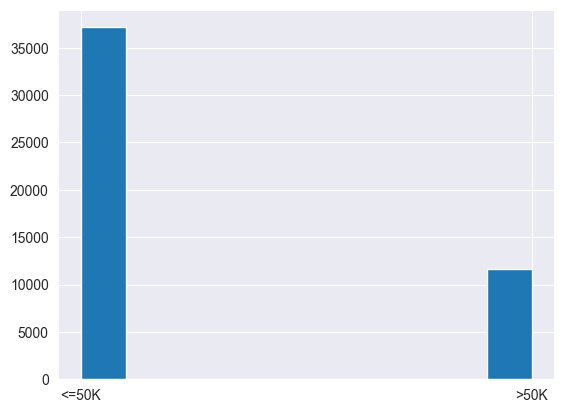

In [479]:
plt.hist(x="income", data=df)

In [480]:
NumericC = df.select_dtypes("int64","float").columns
NumericC

Index(['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='str')

In [481]:
CategoricC = df.select_dtypes(include=["str","object"]).columns
CategoricC

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'gender', 'native-country', 'income'],
      dtype='str')

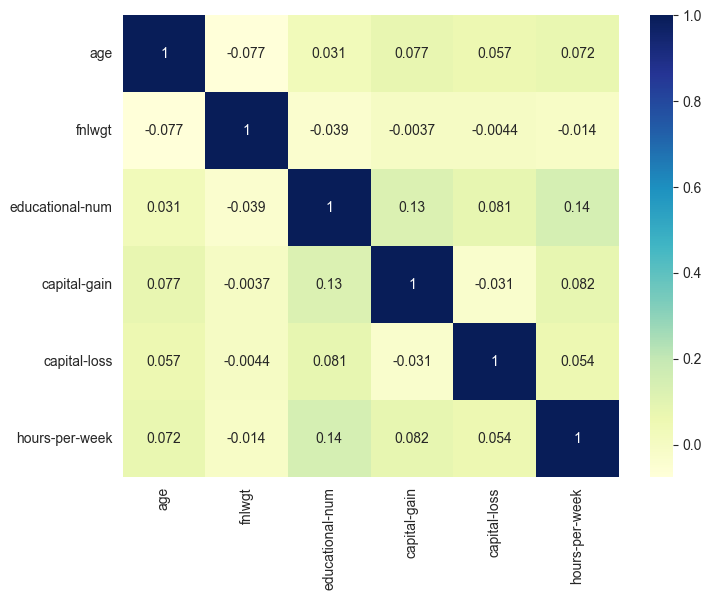

In [482]:
plt.figure(figsize=(8, 6))
Corr = sns.heatmap(df[NumericC].corr(), annot=True, cmap="YlGnBu")

In [483]:
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [484]:
df["native-country"].value_counts(normalize=True) * 100

native-country
United-States                 91.345212
Mexico                         1.981869
Philippines                    0.614775
Germany                        0.429301
Puerto-Rico                    0.383453
Canada                         0.379285
El-Salvador                    0.323018
India                          0.314682
Cuba                           0.287590
England                        0.264666
China                          0.254246
South                          0.239658
Jamaica                        0.220902
Italy                          0.218818
Dominican-Republic             0.214650
Japan                          0.191727
Guatemala                      0.183391
Poland                         0.181307
Vietnam                        0.179223
Columbia                       0.177139
Haiti                          0.156299
Portugal                       0.139627
Taiwan                         0.135459
Iran                           0.122955
Nicaragua                

In [485]:
df["native-country"] = df["native-country"].fillna("United-States")

In [486]:
df["native-country"] = np.where(df["native-country"] == "United-States", "United-States", "Other")

In [487]:
df["native-country"].value_counts(normalize=True) * 100

native-country
United-States    91.497072
Other             8.502928
Name: proportion, dtype: float64

In [488]:
df = df.drop("fnlwgt", axis=1)

In [489]:
df = df.drop("education", axis=1)

In [490]:
df.head()

,age,workclass,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [491]:
df["marital-status"].unique()

<ArrowStringArray>
[        'Never-married',    'Married-civ-spouse',               'Widowed',
              'Divorced',             'Separated', 'Married-spouse-absent',
     'Married-AF-spouse']
Length: 7, dtype: str

In [492]:
NeverMarried = ["Never-married", "Widowed", "Divorced", "Separated"]

df["marital-status"] = np.where(df["marital-status"].isin(NeverMarried),"Not-Married", "Married")


# for i, items in df["marital-status"].items():
#    if items in ["Never-married", "Widowed", "Divorced", "Separated"]:
#         df.loc[i, "marital-status"] = "Not-Married"
#     else:
#         df.loc[i, "marital-status"] = "Married"

In [493]:
df["marital-status"].unique()

<ArrowStringArray>
['Not-Married', 'Married']
Length: 2, dtype: str

In [494]:
df["marital-status"].value_counts()

marital-status
Not-Married    25798
Married        23044
Name: count, dtype: int64

In [495]:
df["relationship"].unique()

<ArrowStringArray>
['Own-child', 'Husband', 'Not-in-family', 'Unmarried', 'Wife',
 'Other-relative']
Length: 6, dtype: str

In [496]:
df = df.drop("relationship", axis=1)

In [497]:
df.head()

,age,workclass,educational-num,marital-status,occupation,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,7,Not-Married,Machine-op-inspct,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married,Farming-fishing,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married,Protective-serv,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married,Machine-op-inspct,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,10,Not-Married,NaN,White,Female,0,0,30,United-States,<=50K


In [498]:
def group_workclass(x):
    if x == "Private":
        return "Private"
    elif x in ["Self-emp-not-inc", "Self-emp-inc"]:
        return "Self-employed"
    elif x in ["Federal-gov", "State-gov", "Local-gov"]:
        return "Government"
    else:
        return "Other"

df["workclass"] = df["workclass"].apply(group_workclass)

In [499]:
df["workclass"].unique()

<ArrowStringArray>
['Private', 'Government', 'Other', 'Self-employed']
Length: 4, dtype: str

In [500]:
df["occupation"] = df["occupation"].fillna("Unknown")

In [501]:
for col in ["workclass", "occupation", "native-country"]:
    df[col] = df[col].fillna(df[col].mode()[0])

In [502]:
df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})

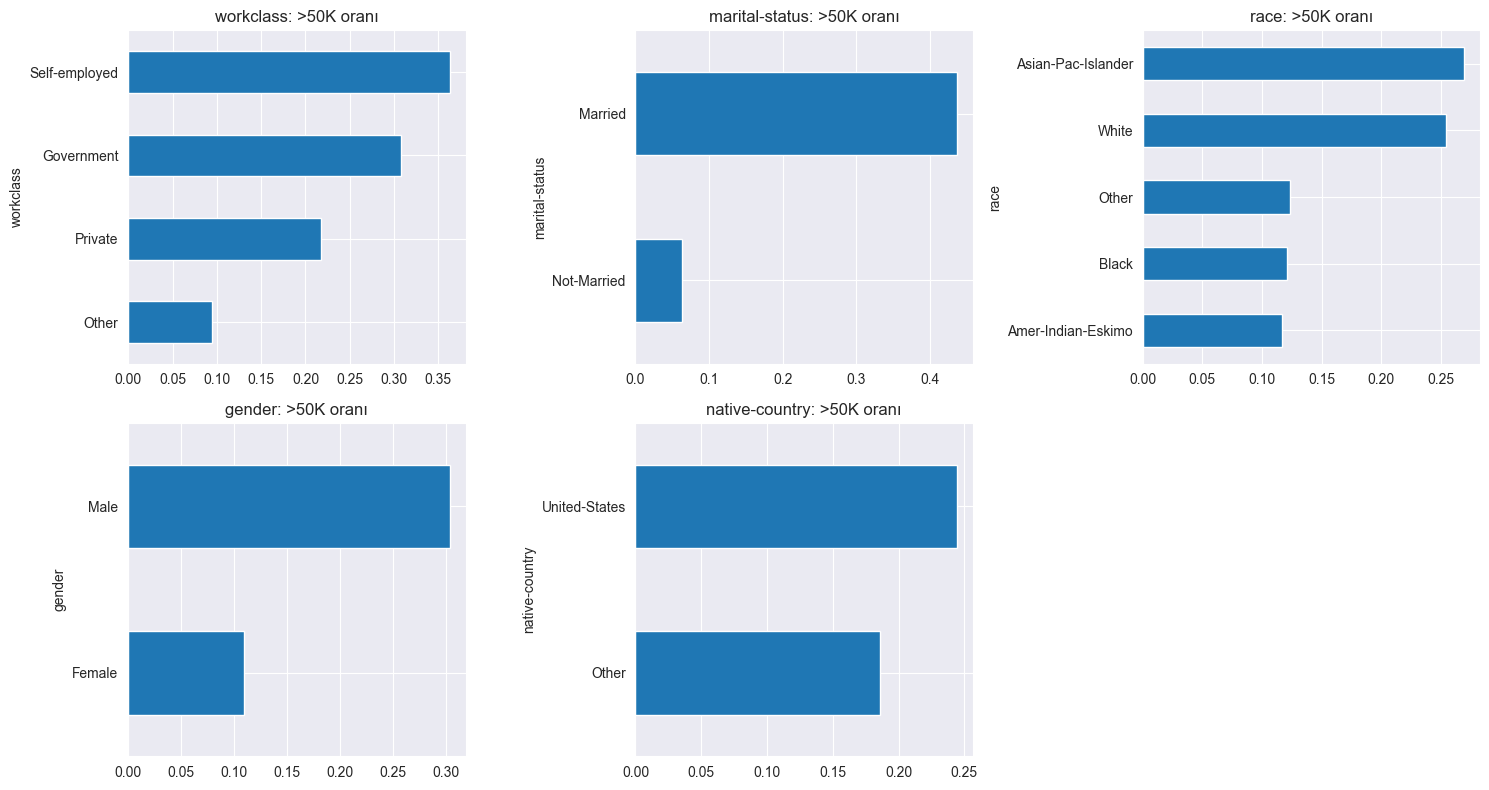

In [503]:
cat_cols = ["workclass", "marital-status", "race", "gender", "native-country"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, cat_cols):
    df.groupby(col)["income"].mean().sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"{col}: >50K oranı")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

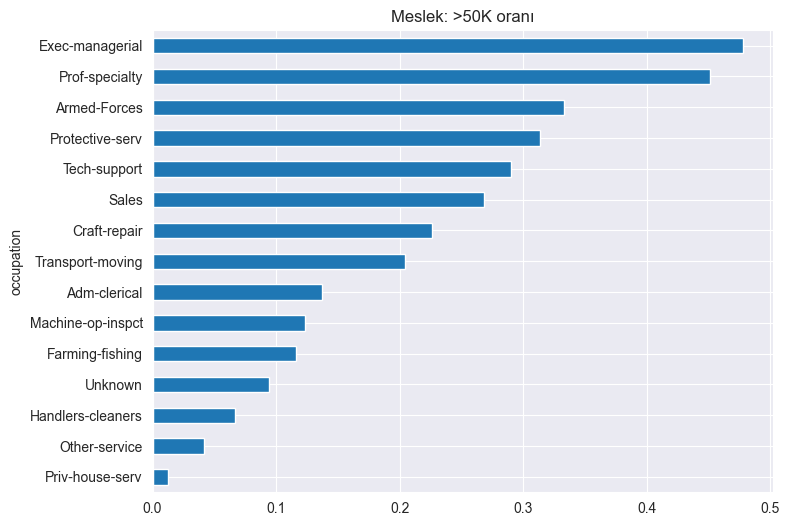

In [504]:
df.groupby("occupation")["income"].mean().sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Meslek: >50K oranı")
plt.show()

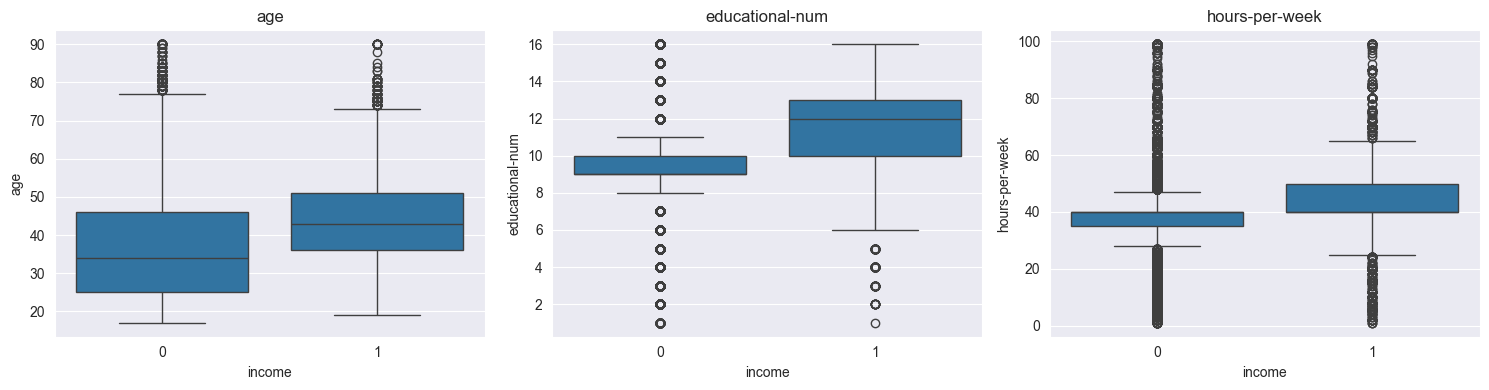

In [505]:
num_cols = ["age", "educational-num", "hours-per-week"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="income", y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [506]:
df = pd.get_dummies(df, drop_first=True, dtype=int)

In [507]:
df.head().T

,0,1,2,3,4
age,25,38,28,44,18
educational-num,7,9,12,10,10
capital-gain,0,0,0,7688,0
capital-loss,0,0,0,0,0
hours-per-week,40,50,40,40,30
income,0,0,1,1,0
workclass_Other,0,0,0,0,1
workclass_Private,1,1,0,1,0
workclass_Self-employed,0,0,0,0,0
marital-status_Not-Married,1,0,0,0,1


In [508]:
from sklearn.model_selection import train_test_split

In [509]:
X = df.drop("income", axis=1)
y = df["income"]

In [510]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [511]:
NumC = ["age", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]

In [512]:
from sklearn.preprocessing import StandardScaler

In [513]:
scaler = StandardScaler()

In [514]:
X_train[NumC] = scaler.fit_transform(X_train[NumC])
X_test[NumC] = scaler.transform(X_test[NumC])

In [515]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7431
           1       0.74      0.58      0.65      2338

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.84      0.85      0.85      9769



In [516]:
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVC": SVC(),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    results.append(
        {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        }
    )

pd.DataFrame(results).sort_values("F1", ascending=False)

,Model,Accuracy,Precision,Recall,F1
5,Random Forest,0.852902,0.729496,0.612489,0.665892
1,SVC,0.858430,0.769014,0.583832,0.663749
0,Logistic Regression,0.851674,0.740921,0.584688,0.653598
3,KNN,0.838366,0.680973,0.610778,0.643968
4,Decision Tree,0.827413,0.651911,0.598375,0.623996
2,Naive Bayes,0.745317,0.481259,0.823781,0.607571


In [517]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVC": SVC(),
    "Random Forest": RandomForestClassifier(random_state=42),
}

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring="f1")
    print(name, scores.mean())

Logistic Regression 0.6490917977272735
SVC 0.6522525148745009
Random Forest 0.6490002665435458


In [518]:
from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators": [100, 300],
    "max_depth": [10, 20],
    "class_weight": ["balanced"],
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), params, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'class_weight': 'balanced', 'max_depth': 20, 'n_estimators': 300}
0.69548894537489


In [519]:
from sklearn.metrics import classification_report

best = grid.best_estimator_
print(classification_report(y_test, best.predict(X_test)))

              precision    recall  f1-score   support

           0       0.93      0.85      0.89      7431
           1       0.62      0.80      0.70      2338

    accuracy                           0.84      9769
   macro avg       0.78      0.82      0.79      9769
weighted avg       0.86      0.84      0.84      9769



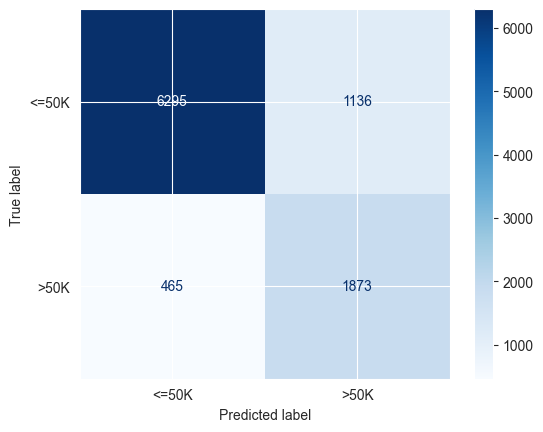

In [520]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["<=50K", ">50K"], cmap="Blues")
plt.show()

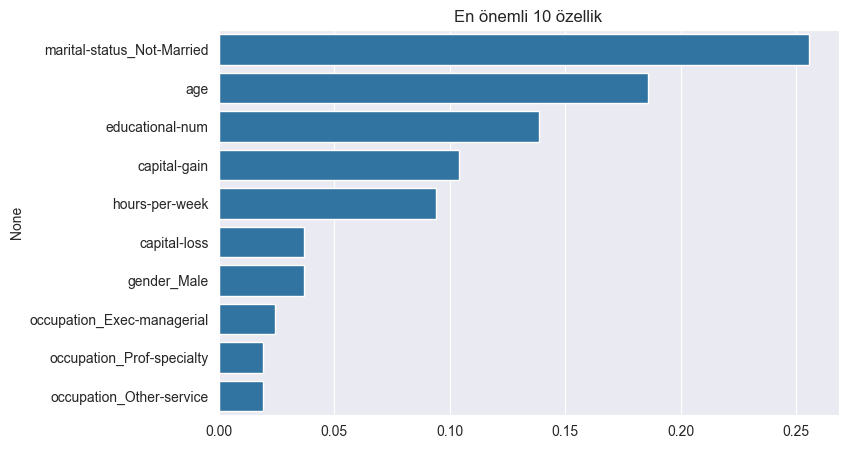

In [521]:
z = pd.Series(best.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=z.values, y=z.index)
plt.title("En önemli 10 özellik")
plt.show()

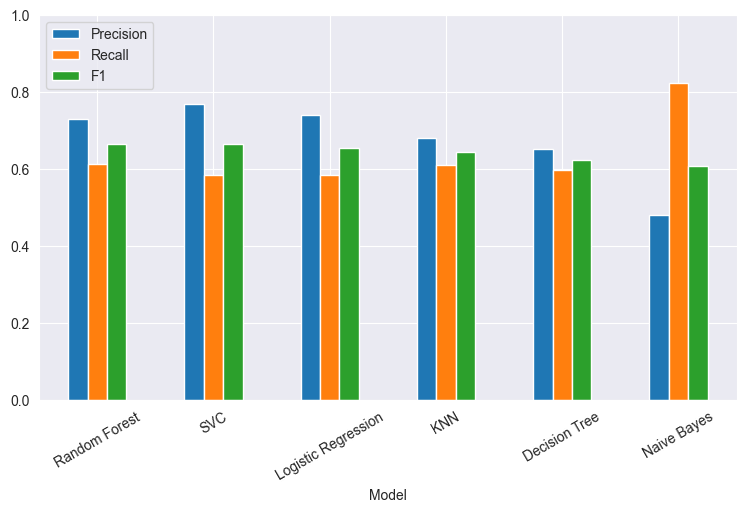

In [522]:
Results = pd.DataFrame(results).sort_values("F1", ascending=False)

Results.set_index("Model")[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 5))
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.show()